In [12]:
from ccvtools import rawio
import imageio.v2 as iio
import numpy as np
from tqdm import tqdm

%matplotlib ipympl
import matplotlib.pyplot as plt 

In [25]:
files = [
    # "H:/yamlsaving/aptina1.ccv",
    "D:/yamlsaving/pylon1.ccv"
    # "G:/yamlsaving/pylon4.ccv"
]

In [26]:
framerate = 100

In [27]:
readers = [iio.get_reader(file) for file in files]
print("Number of frames: ", [len(r) for r in readers])

Number of frames:  [913]


In [28]:
# Read all timestamps from video files for further analysis
timestamps_all = []
fr_idxs_all = []
for i_c, r in enumerate(readers):
    timestamps = []
    fr_idxs = []
    for i_f in range(len(r)):
        md = readers[i_c].get_meta_data(i_f)
        timestamps.append(md["timestamp"])
        fr_idxs.append(md["index"])
    timestamps_all.append(np.array(timestamps))
    fr_idxs_all.append(np.array(fr_idxs))

==== Cam 0 ====
Maximum step in frame idx:  1
Maximum and minimum local fps:  99.9971303515359 99.99658905428768
Number of frames with local fps < 75/s 0


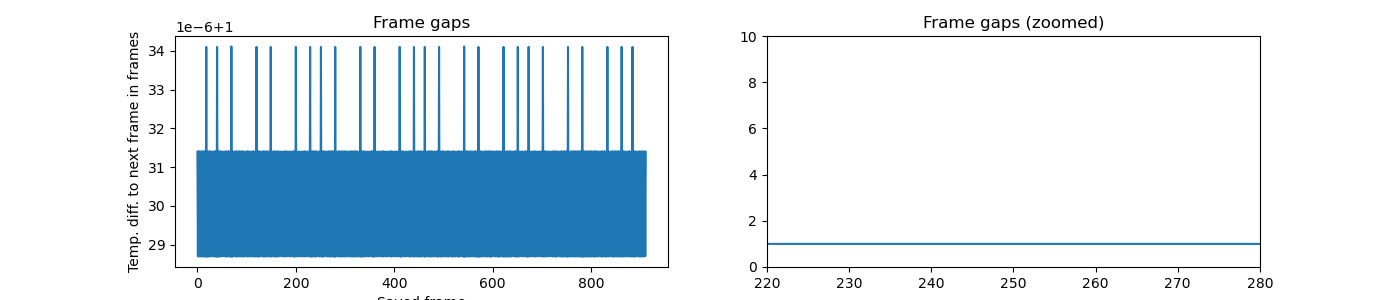

In [29]:
# Plot gaps between frames based on camera times
fig, axs = plt.subplots(1,2, figsize=(14,3))
for i_id, (ids, ts) in enumerate(zip(fr_idxs_all, timestamps_all)):
    print(f"==== Cam {i_id} ====")
    print("Maximum step in frame idx: ", np.max(np.diff(ids)))
    print("Maximum and minimum local fps: ", 1/np.min(np.diff(ts)), 1/np.max(np.diff(ts)))
    print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))
    axs[0].plot(np.diff(ts)*framerate)
    axs[0].set_title("Frame gaps")
    axs[0].set_xlabel("Saved frame")
    axs[0].set_ylabel("Temp. diff. to next frame in frames")
    axs[1].plot(np.diff(ts)*framerate)
    axs[1].set_xlim((220,280))
    axs[1].set_ylim((0,10))
    axs[1].set_title("Frame gaps (zoomed)")
    axs[0].set_xlabel("Saved frame")

In [30]:
# Print first 10 saved frame idxs and cam times
for i_cam in range(len(files)):
    print("Cam ", i_cam)
    timestamps = []
    for i in range(10):
        md = readers[i_cam].get_meta_data(i)
        print(md)
        timestamps.append(md["timestamp"])
    timestamps = np.array(timestamps)
    print(np.diff(timestamps)/(1/framerate))

Cam  0
{'index': 1, 'timestamp': 698160.033992736}
{'index': 2, 'timestamp': 698160.04399305}
{'index': 3, 'timestamp': 698160.053993337}
{'index': 4, 'timestamp': 698160.063993651}
{'index': 5, 'timestamp': 698160.073993965}
{'index': 6, 'timestamp': 698160.083994279}
{'index': 7, 'timestamp': 698160.093994566}
{'index': 8, 'timestamp': 698160.10399488}
{'index': 9, 'timestamp': 698160.113995194}
{'index': 10, 'timestamp': 698160.123995481}
[1.0000314  1.0000287  1.0000314  1.00003141 1.0000314  1.0000287
 1.0000314  1.0000314  1.0000287 ]


In [31]:
print(r.get_data(5).shape)

(1080, 1440)


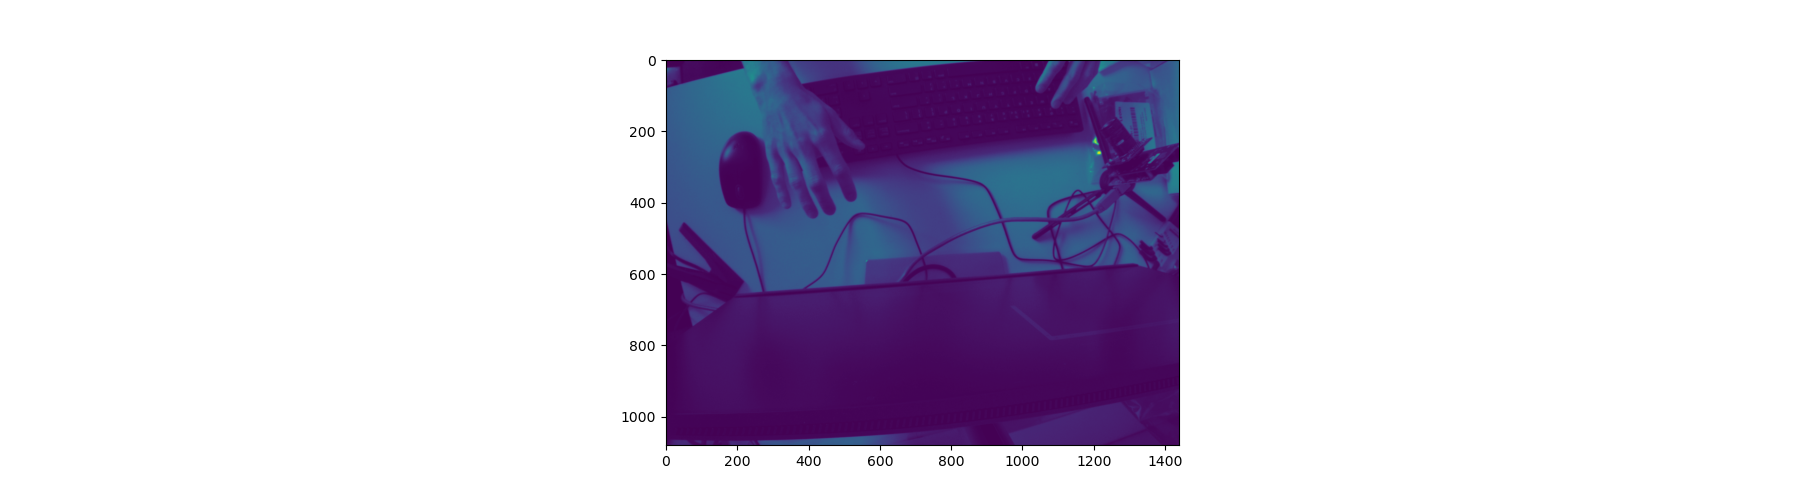

In [32]:
# Plot single frame from each cam
fig, axs = plt.subplots(1,len(files), figsize=(18,5), squeeze=False)
for ax,r in zip(axs[0],readers):
    ax.imshow(r.get_data(100))

In [33]:
# Print local frame rate
1/np.diff(timestamps)

array([99.99686028, 99.99713035, 99.99686028, 99.99685912, 99.99686028,
       99.99713035, 99.99686028, 99.99686028, 99.99713035])